In [3]:
# Import libraries.
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches



In [4]:
# Import the dataset.
num = pd.read_excel('GPPS_2026_Practice_results_(weighted)_(Excel)_PUBLIC.xlsx')

In [7]:
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)

ID_COLS = ["region_name", "ics_code", "ics_name", "pcn_code", "pcn_name",
           "practice_code", "practice_name"]




In [8]:
def load_sheet(sheet):
    df = pd.read_excel(FILE, sheet_name=sheet, header=6)
    # tidy names: strip stray spaces/newlines
    df.columns = [" ".join(str(c).split()) for c in df.columns]
    return df

In [13]:
FILE = "GPPS_2026_Practice_results_(weighted)_(Excel)_PUBLIC.xlsx"   # must match your file exactly

num = pd.read_excel(FILE, sheet_name="Overall experience", header=6)
num.columns = [" ".join(str(c).split()) for c in num.columns]
num.head()

,Region name,ICS code,ICS name,PCN code,PCN name,Practice code,Practice name,Total survey forms distributed,Total completed forms received,Response rate (%),Overall experience of GP practice - Unweighted total responses,% Very good,% Fairly good,% Neither good nor poor,% Fairly poor,% Very poor,% Good (total),% Good - lower limit 95% confidence interval,% Good - upper limit 95% confidence interval
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2968415,654714,0.220560,651774,0.455096,0.312264,0.128698,0.061738,0.042204,0.76736,0.765757,0.768955
1,EAST OF ENGLAND COMMISSIONING REGION,D7T5G,ESSEX INTEGRATED CARE SYSTEM,NaN,NaN,F81014,CHURCH LANE SURGERY,670,171,0.255224,171,0.209514,0.374197,0.224803,0.130526,0.060959,0.583711,0.513343,0.650825
2,EAST OF ENGLAND COMMISSIONING REGION,D7T5G,ESSEX INTEGRATED CARE SYSTEM,NaN,NaN,F81019,MAYFLOWER MEDICAL CENTRE,363,106,0.292011,105,0.399966,0.26406,0.204848,0.024726,0.1064,0.664026,0.416360,0.845575
3,EAST OF ENGLAND COMMISSIONING REGION,D7T5G,ESSEX INTEGRATED CARE SYSTEM,NaN,NaN,F81031,MURREE MEDICAL GROUP,606,114,0.188119,114,0.178377,0.256247,0.245509,0.113259,0.206608,0.434624,0.349918,0.523328
4,EAST OF ENGLAND COMMISSIONING REGION,D7T5G,ESSEX INTEGRATED CARE SYSTEM,NaN,NaN,F81044,THE ARDLEIGH SURGERY,304,106,0.348684,106,0.453612,0.320991,0.128176,0.047341,0.04988,0.774603,0.694924,0.838313


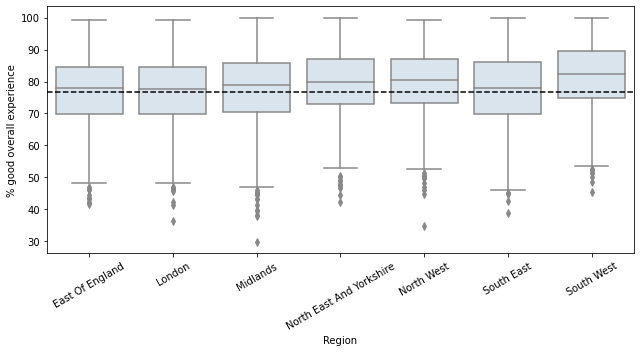

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

FILE = "GPPS_2026_Practice_results_(weighted)_(Excel)_PUBLIC.xlsx"   # exactly as your file is named

df = pd.read_excel(FILE, sheet_name="Overall experience", header=6)
df.columns = [" ".join(str(c).split()) for c in df.columns]

good = "% Good (total)"
base = "Overall experience of GP practice - Unweighted total responses"

england = df[df["Practice code"].isna()]
practices = df[df["Practice code"].notna()].copy()

practices[good] = pd.to_numeric(practices[good], errors="coerce") * 100
practices[base] = pd.to_numeric(practices[base], errors="coerce")
eng = float(england[good].iloc[0]) * 100

big = practices[practices[base] >= 30].copy()

big["Region"] = big["Region name"].str.replace(" COMMISSIONING REGION", "").str.title()

fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=big, x="Region", y=good, ax=ax, color="#d6e4f0")
ax.axhline(eng, color="black", ls="--")
ax.tick_params(axis="x", rotation=30)
ax.set_ylabel("% good overall experience")
plt.tight_layout()
plt.show()

In [16]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

FILE = "GPPS_2026_Practice_results_(weighted)_(Excel)_PUBLIC.xlsx"   # match your file name
CODE = "F81014"                                                       # your practice code

def load(sheet):
    d = pd.read_excel(FILE, sheet_name=sheet, header=6)
    d.columns = [" ".join(str(c).split()) for c in d.columns]
    return d

In [17]:
health = load("Your health")
base_col = [c for c in health.columns
            if c.startswith("Long-term physical or mental health conditions")][0]

england = health[health["Practice code"].isna()]
h = health[health["Practice code"].notna()].copy()
h["diabetes_%"] = pd.to_numeric(h["% Diabetes"], errors="coerce") * 100
h["base"] = pd.to_numeric(h[base_col], errors="coerce")
h = h[h["base"] >= 30]                                  # drop tiny samples

eng_diab = float(england["% Diabetes"].iloc[0]) * 100
me = h[h["Practice code"] == CODE].iloc[0]
print(f"England: {eng_diab:.1f}%  |  {me['Practice name']}: {me['diabetes_%']:.1f}%")
print("Percentile:", round((h["diabetes_%"] < me["diabetes_%"]).mean() * 100, 1))

England: 8.1%  |  CHURCH LANE SURGERY: 6.5%
Percentile: 32.2


In [18]:
print(h.groupby("ICS name")["diabetes_%"].mean().sort_values(ascending=False).head(10).round(1))


ICS name
BLACK COUNTRY INTEGRATED CARE SYSTEM                            10.5
BIRMINGHAM AND SOLIHULL INTEGRATED CARE SYSTEM                  10.2
STAFFORDSHIRE AND STOKE-ON-TRENT INTEGRATED CARE SYSTEM          9.4
WEST YORKSHIRE INTEGRATED CARE SYSTEM                            9.3
NORTH EAST LONDON INTEGRATED CARE SYSTEM                         9.3
LEICESTER, LEICESTERSHIRE AND RUTLAND INTEGRATED CARE SYSTEM     9.2
NORTH EAST AND NORTH CUMBRIA INTEGRATED CARE SYSTEM              9.0
GREATER MANCHESTER INTEGRATED CARE SYSTEM                        9.0
KENT AND MEDWAY INTEGRATED CARE SYSTEM                           9.0
SOUTH YORKSHIRE INTEGRATED CARE SYSTEM                           8.9
Name: diabetes_%, dtype: float64


Correlation: -0.12


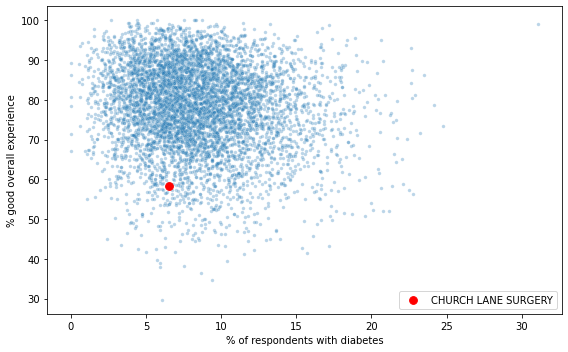

In [19]:
oe = load("Overall experience")
oe = oe[oe["Practice code"].notna()].copy()
oe["good_%"] = pd.to_numeric(oe["% Good (total)"], errors="coerce") * 100
m = h.merge(oe[["Practice code", "good_%"]], on="Practice code").dropna(subset=["diabetes_%", "good_%"])
print("Correlation:", round(m["diabetes_%"].corr(m["good_%"]), 2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=m, x="diabetes_%", y="good_%", s=12, alpha=0.3, ax=ax)
mine = m[m["Practice code"] == CODE]
ax.scatter(mine["diabetes_%"], mine["good_%"], color="red", s=60, label=me["Practice name"])
ax.set_xlabel("% of respondents with diabetes")
ax.set_ylabel("% good overall experience")
ax.legend()
plt.tight_layout()
plt.show()